# Lab 5: Linear Regression I
Before you turn this assignment in, make sure everything runs as expected. First, **restart the kernel** (in the menubar, select Kernel$\rightarrow$Restart) and then **run all cells** (in the menubar, select Cell$\rightarrow$Run All).

Add as many comments as you could when you solve the problem, which can help your remember what you have done.


***Submission***: For Python people, submit this Jupyter Notebook only

Name = "Noah Runions"

***Note:*** The functions/code provided are one of many ways that can work. Feel free to use functions you are more familiar with!\
***Figures:*** For any figures, label axis and title clearly for full points. 

## Lab Objectives:

1. Calculate linear regression variables and confidence intervals using the Galapagos Island data set from the textbook.
2.	Plot data with confidence intervals.


  
## Lab Activities: 
This lab has two parts, each worth 30 points, for a total of 60 points. Be sure to follow the instructions for both Part A and Part B.

In [ ]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

## Part 5A (30 points). Linear Regression with Galapagos Island Data

1. Read the txt file and import data
2. Plot a scatter plot for visualization

In [ ]:
# Read data
plant_area = pd.read_csv(r'C:\Users\noahr\Documents\Python Scripts\OCNG470\Lab5\Plant_Area.txt', sep = r'\s+')

# Add log columns
plant_area['log_Species'] = np.log10(plant_area['Species'])
plant_area['log_Area'] = np.log10(plant_area['Area'])

# Check that it looks good
# plant_area

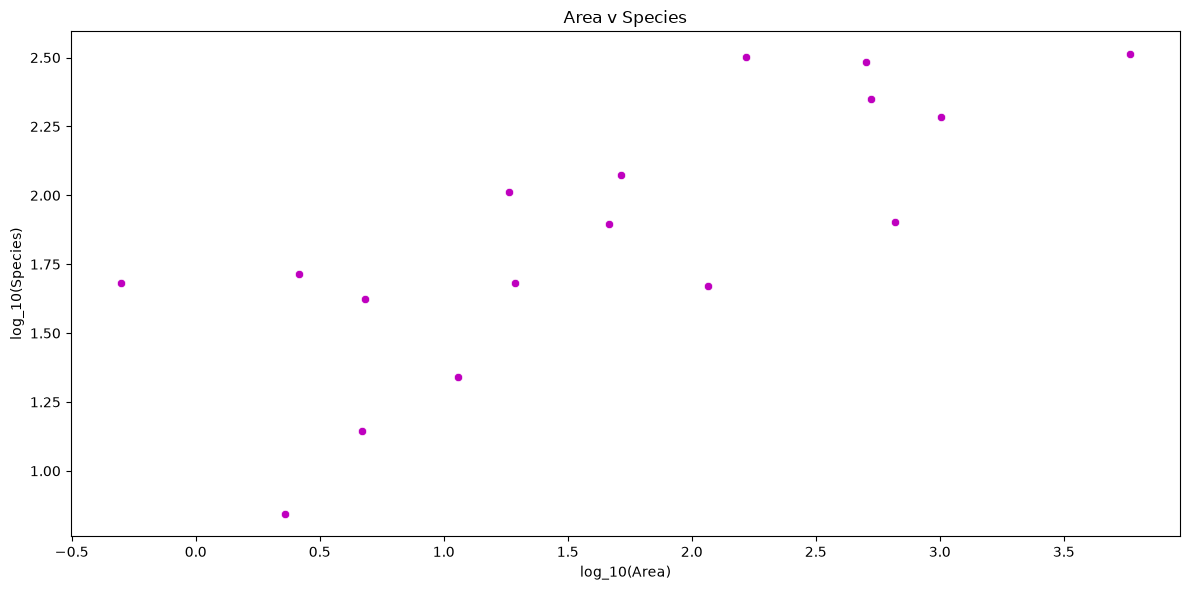

In [12]:
# Plot data
plt.figure(figsize = (12, 6))
sns.scatterplot(data = plant_area, x='log_Area', y='log_Species', color = 'm')
plt.xlabel('log_10(Area)')
plt.ylabel('log_10(Species)')
plt.title('Area v Species')

plt.tight_layout()
plt.show()

3. Build linear regression model
- Calculating the predicted y to construct a regression line with slope and intercept using the function stats.linregress()
- Calculate the confidence intervals step by step following the class demo
- Plot the confidence interval (do not use sns.regplot for this one, calculating the interval from scratch)

In [16]:
# getting x, y, and lin reg  y vals
plant_linreg = stats.linregress(plant_area['log_Area'], plant_area['log_Species'])
Y= plant_area['log_Species']
X = plant_area['log_Area']
Y_predict = plant_linreg.intercept + plant_linreg.slope * X

# getting t val
confidence = 0.95
alpha = 1 - confidence
n = 14
degrees_of_freedom = n - 2
t_value = stats.t.ppf(1 - alpha/2, degrees_of_freedom)

# getting std error
residuals = Y - Y_predict
se=np.sqrt(np.sum(residuals**2)/degrees_of_freedom)

# getting sum of squared deviations
X_mean = np.mean(X)
sxx = np.sum((X - X_mean)**2)

# getting std error of fit, and confidence upper/lower bounds
se_fit = se * np.sqrt(1/n + (X - X_mean)**2 / sxx)
upper , lower = Y_predict + t_value * se_fit , Y_predict - t_value * se_fit

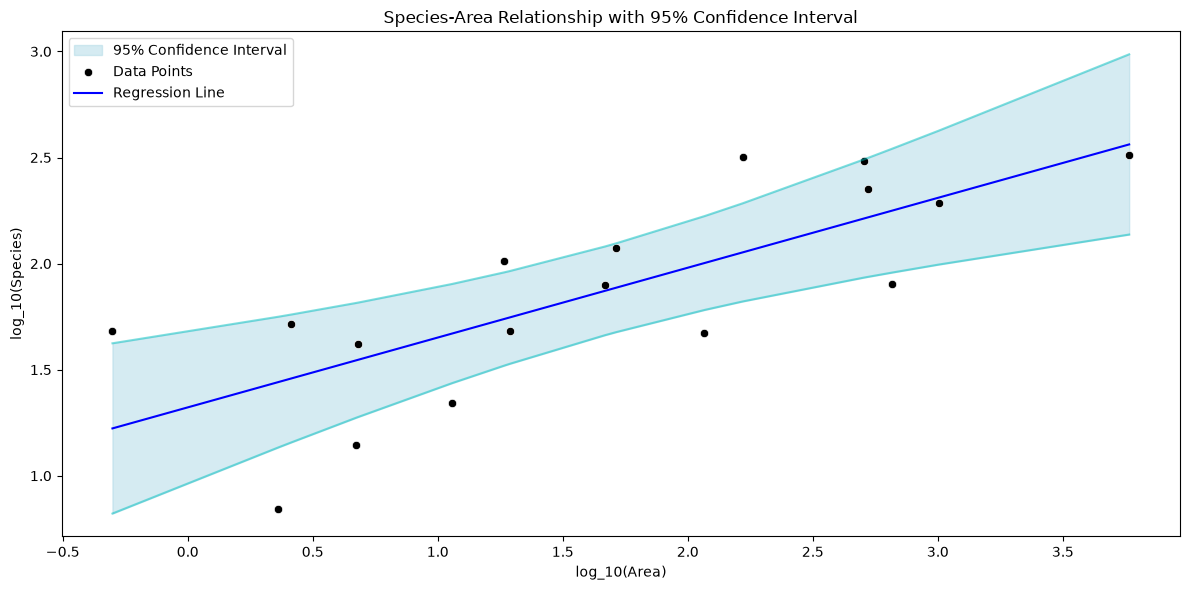

In [19]:
# plotting data
plt.figure(figsize=(12, 6))
plt.fill_between(X.sort_values(), lower.sort_values(), upper.sort_values(), color='lightblue', alpha=0.5, label='95% Confidence Interval')
plt.plot(X.sort_values(), upper.sort_values(), color='c', alpha=0.5)
plt.plot(X.sort_values(), lower.sort_values(), color='c', alpha=0.5)
sns.scatterplot(data=plant_area, x='log_Area', y='log_Species', color = 'k', label= 'Data Points')
sns.lineplot(x=X, y=Y_predict, color='b', label= 'Regression Line')

plt.xlabel('log_10(Area)')
plt.ylabel('log_10(Species)')
plt.title('Species-Area Relationship with 95% Confidence Interval')
plt.legend()
plt.tight_layout()
plt.show()

## Part 5B (30 pints); Investigating the Effect of Noise
1. Define basic variables and add noise
- construct a linear relationship y = 2*x + 4 
- initilize the x using np.linspace function, initialize 10 x values
- calculate y
- add random numbers to the y using np.random.rand(10)
- mutiply the random numbers by a factor of 1,3,6,9,12,18,36 respectively and then
2. Examine the data by plotting with varying noise
- you can use sns.regplot for easier plotting
- make sure you have 95% confidence interval for each plots
3. Calculate the P and R values for each factor and plot them vs the factors

In [7]:
# perfect data
pX = np.linspace(0, 10, 10)
pY = pX * 2 + 4

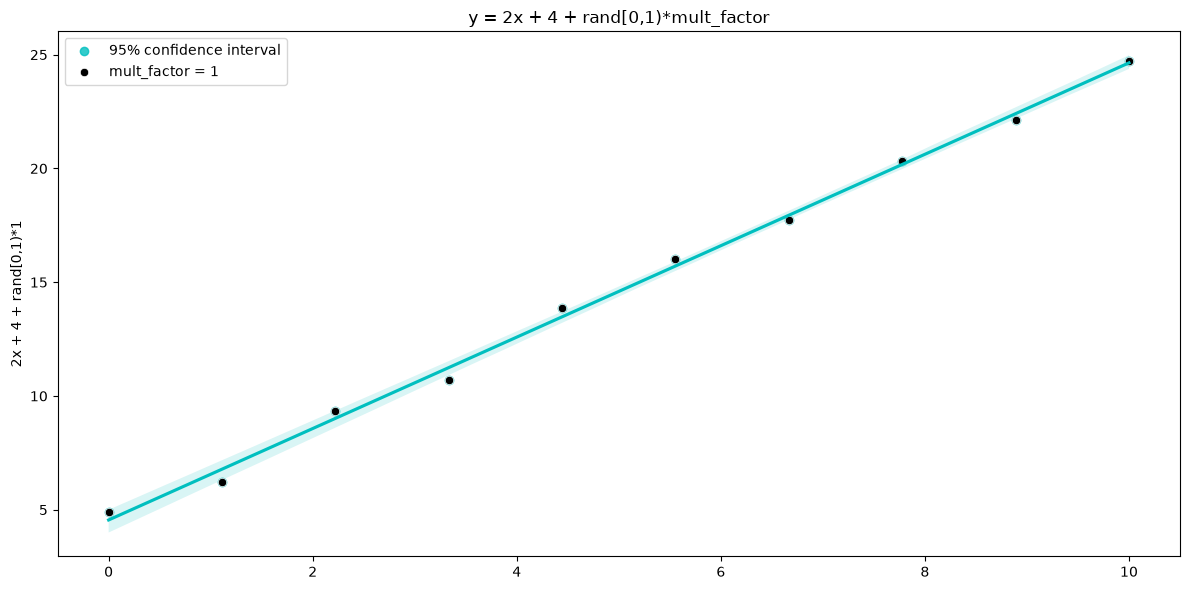

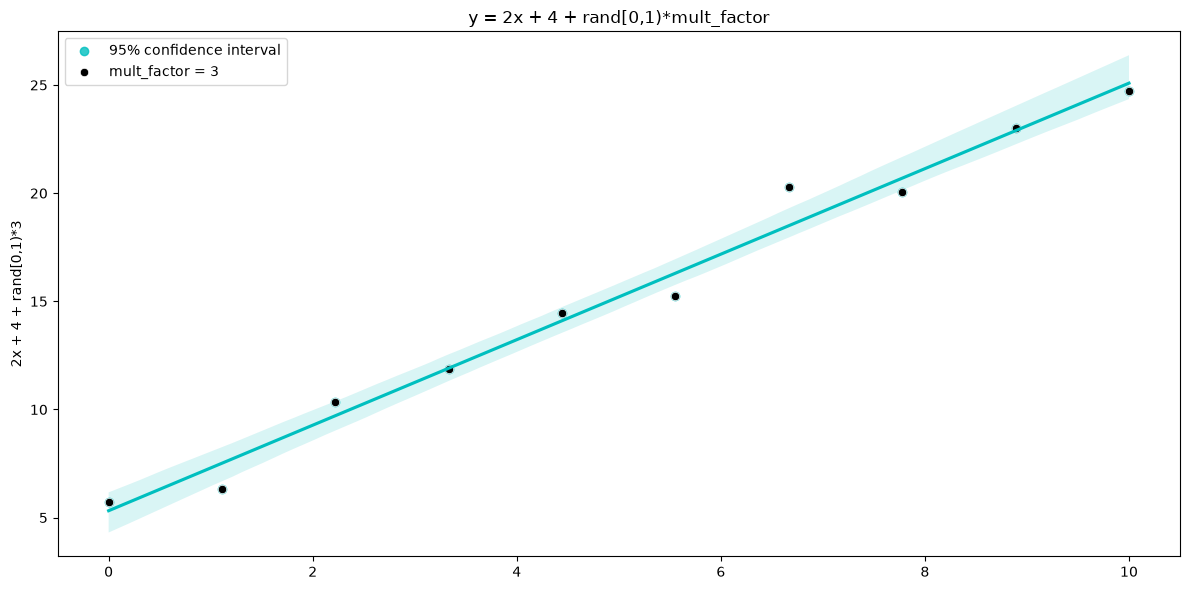

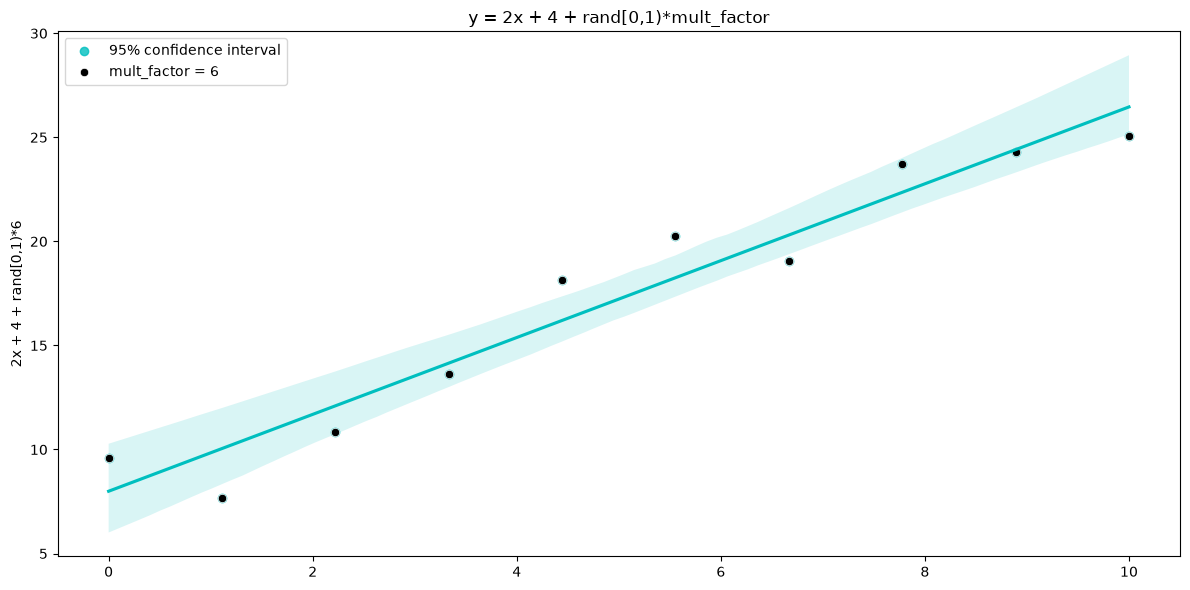

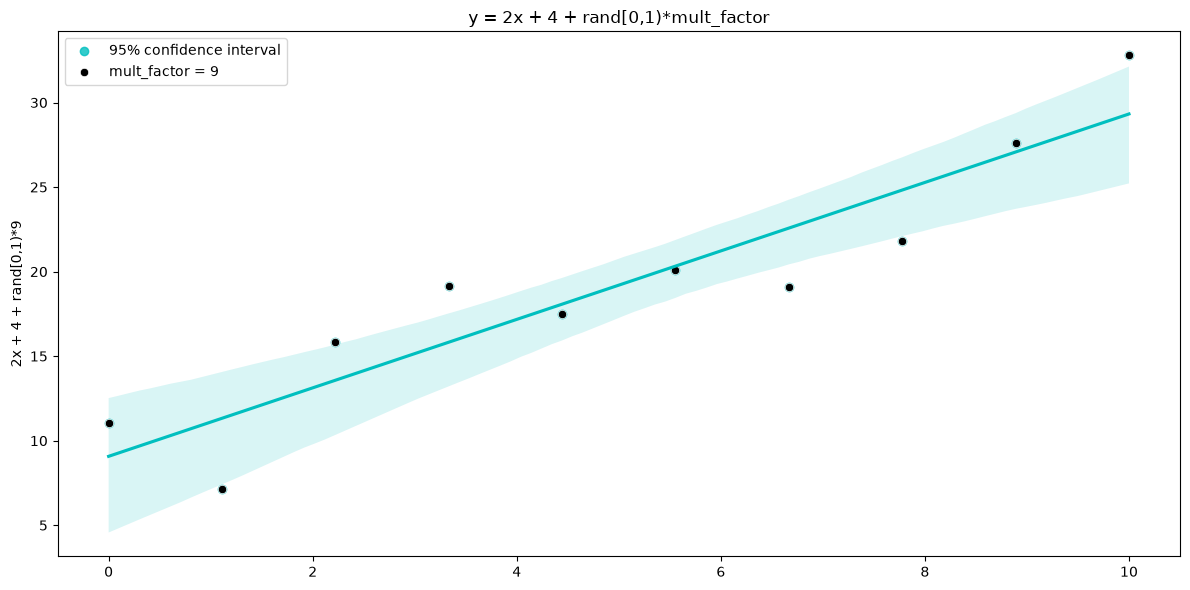

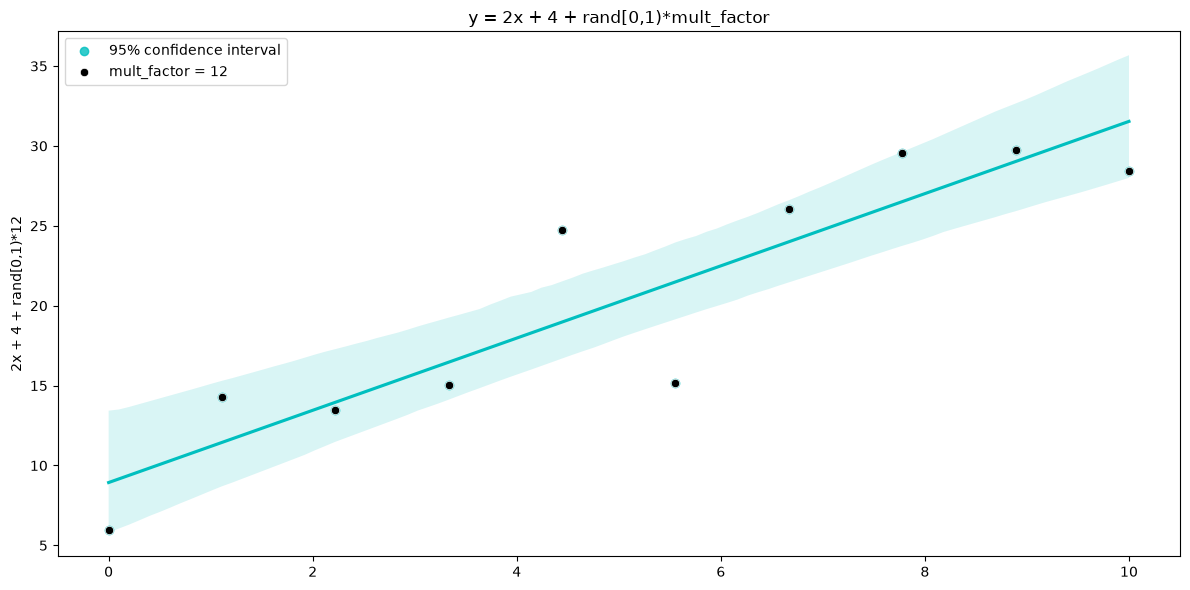

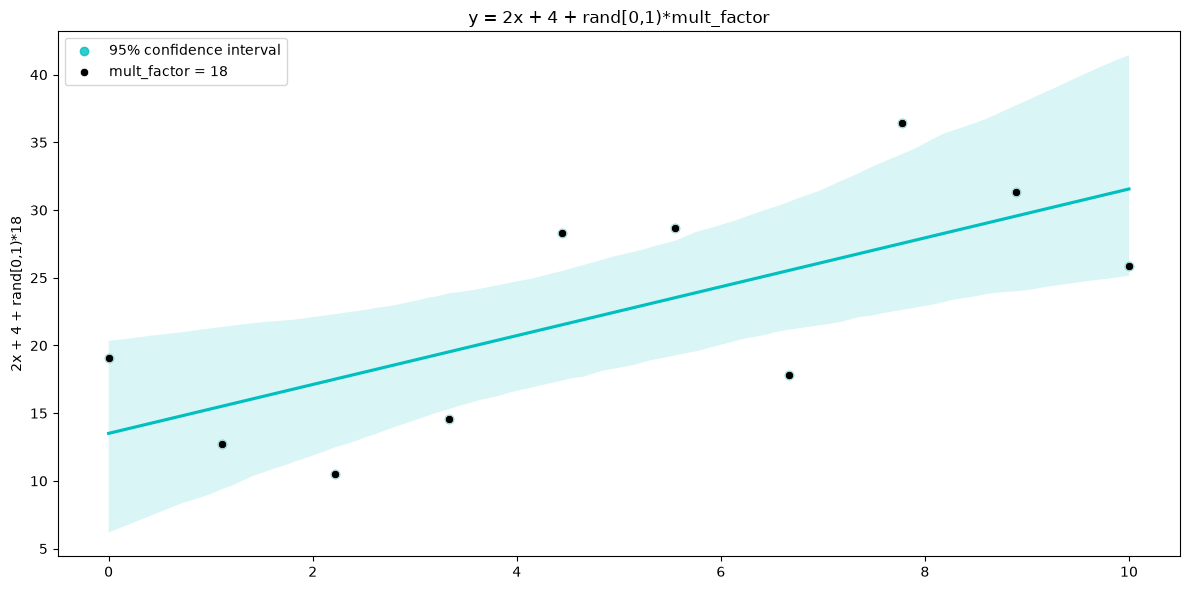

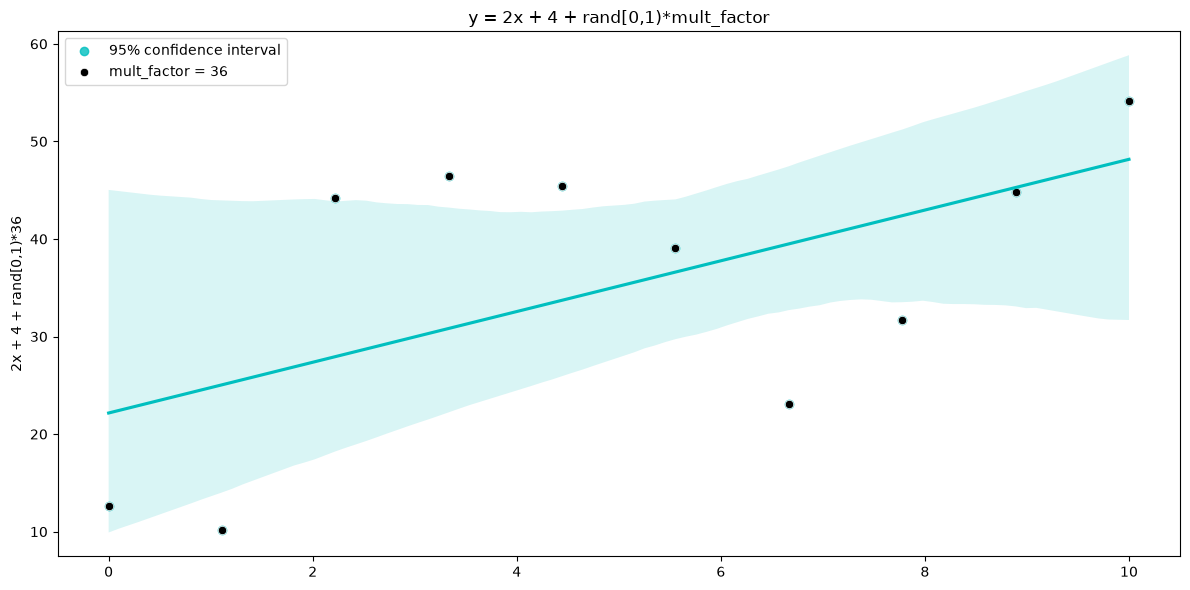

In [32]:
# setting mult factors and empty r and p val lists
factors_multiple, r_values, p_values = [1,3,6,9,12,18,36], [], []

# plots
for factor in factors_multiple:
    y_noise = pY + factor * np.random.rand(10)
    plt.figure(figsize=(12, 6))
    sns.regplot(x=pX, y=y_noise, color = 'c', ci=95, label = r'95% confidence interval')
    sns.scatterplot(x=pX, y=y_noise, color = 'k', label = f'mult_factor = {factor}')

    plt.title('y = 2x + 4 + rand[0,1)*mult_factor')
    plt.ylabel(f'2x + 4 + rand[0,1)*{factor}')
    plt.legend()
    plt.tight_layout()
    plt.show()

    slope, intercept, r_value, p_value, std_err = stats.linregress(pX, y_noise)
    r_values.append(r_value)
    p_values.append(p_value)

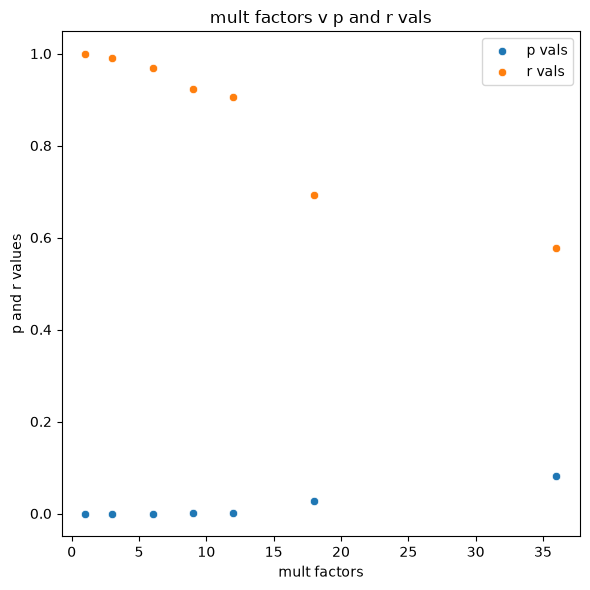

In [34]:
# plotting mult factors v p and r vals
plt.figure(figsize=(6, 6))
sns.scatterplot(x = factors_multiple, y = p_values, label = 'p vals')
sns.scatterplot(x = factors_multiple, y = r_values, label = 'r vals')
plt.title('mult factors v p and r vals')
plt.xlabel('mult factors')
plt.ylabel('p and r values')
plt.legend()
plt.tight_layout()
plt.show()